# CS781 Phase 3 — Decoder + DoRA + BiLSTM + CRF (joint)

Builds on the 0.4857 run. Only change: the decoder is no longer frozen — DoRA adapters on
`q,v` train jointly with the BiLSTM-CRF head.

**DoRA, not AdaLoRA.** AdaLoRA's rank-pruning schedule needs `update_and_allocate(global_step)`
called once per optimiser step. In this loop one optimiser step covers many sub-batched decoder
forwards, so the step count is easy to get wrong and the failure is silent (you get plain LoRA at
`init_r`). DoRA is `use_dora=True` and no schedule. Switch to plain LoRA with one flag to compare.

## What joint training costs

Caching dies — every sentence is re-encoded every epoch. 16,845 train sentences at 128 tokens is
roughly 1 min/epoch; at your old 512 it would have been ~4x that. The token cut is what makes
this affordable at all.

## Memory: documents are chunked during training only

Backprop through a whole document needs every sentence's graph alive at once. Your longest
document is 1816 sentences — at 128 tokens x 768 dims x 19 layers that is ~6.8 GB of
checkpoint boundaries alone. So **training** splits documents into chunks of
`max_chunk_sents` (default 160; your median document is 123, so most are untouched).
**Inference runs whole documents** — no grad, no memory problem, no chunking.

Known approximation: a chunk boundary that is not a real document boundary still contributes
CRF `start`/`end` terms. Only the few long documents are affected and it is 2 terms out of ~160,
so I left the verified CRF untouched rather than complicate it.

## Carried over from the 0.4857 run

128 tokens, last-token(`</s>`)+mean pooling, `clean_text`, max-frequency class weights,
4 positional features, CRF + Viterbi, no sampler, plateau averaging over the final epochs
instead of picking one lucky epoch.

In [ ]:
# CELL 1 — ASSETS

from pathlib import Path
from google.colab import drive
from getpass import getpass
from huggingface_hub import HfApi, hf_hub_download
import os, re, sys, subprocess

subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                        "huggingface_hub", "peft==0.1"])

drive.mount("/content/drive")
DRIVE_ROOT = Path("/content/drive/MyDrive")

drive_files = []
for root, dirs, files in os.walk(DRIVE_ROOT):
    dirs[:] = [d for d in dirs if d not in {".Trash", ".ipynb_checkpoints", "node_modules"}]
    for fn in files:
        drive_files.append(Path(root) / fn)

def normalized_name(p):
    return re.sub(r" \(\d+\)(?=\.)", "", p.name).lower()

def locate_drive_file(filename, preferred_folder=None):
    tgt = filename.lower()
    m = [p for p in drive_files if p.name.lower() == tgt or normalized_name(p) == tgt]
    if preferred_folder:
        pref = [p for p in m if preferred_folder.lower() in str(p.parent).lower()]
        if pref: m = pref
    if not m:
        raise FileNotFoundError(f"Could not find {filename} on Drive.")
    m.sort(key=lambda p: (p.name.lower() != tgt, len(p.parts), str(p).lower()))
    return m[0]

CHECKPOINT_PATH = locate_drive_file("best.pt")
TOKENIZER_JSON  = locate_drive_file("bpe_40k.json")
TOKENIZER_PY    = locate_drive_file("a1_tokenizer.py")

HF_REPO = "Exploration-Lab/CS-781-Capstone"
HF_TOKEN = getpass("HF read token: ")
api = HfApi()
repo_files = api.list_repo_files(repo_id=HF_REPO, repo_type="dataset", token=HF_TOKEN)
phase3 = [f for f in repo_files if "phase_3_rr/" in f.lower()]

def dl(filename):
    tgt = filename.lower()
    m = [f for f in phase3 if Path(f).name.lower() == tgt]
    if not m:
        m = [f for f in phase3 if normalized_name(Path(f)).lower() == tgt]
    if "test" in tgt:        pref = [f for f in m if "/test/" in f.lower()]
    elif "label_vocab" in tgt: pref = m
    else:                    pref = [f for f in m if "/train/" in f.lower()]
    return Path(hf_hub_download(repo_id=HF_REPO, filename=(pref or m)[0],
                                repo_type="dataset", token=HF_TOKEN))

CL_TRAIN, CL_DEV = dl("CL_train.json"), dl("CL_dev.json")
IT_TRAIN, IT_DEV = dl("IT_train.json"), dl("IT_dev.json")
CL_TEST, IT_TEST = dl("CL_test.json"), dl("IT_test.json")
LABEL_VOCAB = dl("label_vocab.json")
CKPT_PATH = CHECKPOINT_PATH

if str(TOKENIZER_PY.parent) not in sys.path:
    sys.path.insert(0, str(TOKENIZER_PY.parent))
print(f"Decoder: {CKPT_PATH}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
HF read token: ··········
Decoder: /content/drive/MyDrive/best.pt


In [ ]:
# CELL 2 — IMPORTS + CONFIG

import json, math, random, zipfile, time, html, unicodedata
from dataclasses import dataclass
from collections import Counter, deque
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.amp import autocast, GradScaler
from torch.utils.checkpoint import checkpoint as grad_ckpt
from sklearn.metrics import f1_score, classification_report

from peft import LoraConfig, get_peft_model

# peft's is_torchao_available() raises on Colab's torchao 0.10.0 even though
# nothing here quantizes. Neutralise the probe in every peft module that bound it.
import sys
for _m in list(sys.modules.values()):
    if _m is not None and getattr(_m, "__name__", "").startswith("peft") \
       and hasattr(_m, "is_torchao_available"):
        _m.is_torchao_available = lambda: False
from a1_tokenizer import BPETokenizer

OUTPUT_DIR = DRIVE_ROOT / "CS781_Phase3_DoRA_CRF_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name} ({p.total_memory/1024**3:.1f} GiB)")

@dataclass
class Cfg:
    # Decoder arch — EXACTLY Phase 1
    vocab_size: int = 40_000
    d_model: int = 768
    n_layers: int = 19
    n_query_heads: int = 12
    n_kv_heads: int = 4
    d_ff: int = 2048
    max_seq_len: int = 512          # RoPE buffer is max_seq_len * 2
    rope_theta: float = 10_000.0
    dropout: float = 0.0

    # Sentence encoding
    sent_max_tokens: int = 128
    sent_sub_batch: int = 16        # sentences per decoder forward inside a chunk
    n_pos_feats: int = 4

    # DoRA
    use_dora: bool = True           # False -> plain LoRA, for the ablation
    r: int = 8
    lora_alpha: int = 16
    lora_dropout: float = 0.1
    target_modules = ("q", "v")     # best target set from your earlier LoRA runs

    # Head
    num_labels: int = 13
    bilstm_hidden: int = 256
    bilstm_layers: int = 2
    bilstm_dropout: float = 0.3
    cls_dropout: float = 0.4
    aux_ce_weight: float = 0.5
    class_weight_cap: float = 4.0

    # Training
    epochs: int = 20                # joint training needs far fewer than 60
    grad_accum: int = 4             # in documents
    max_chunk_sents: int = 160      # TRAIN-only document chunking (memory)
    use_grad_ckpt: bool = True
    dora_lr: float = 1e-4           # pretrained weights want small nudges
    head_lr: float = 1e-3
    crf_lr: float = 5e-3
    weight_decay: float = 0.01
    max_grad_norm: float = 5.0
    early_stop_patience: int = 5
    swa_window: int = 5             # average emissions over the final N epochs
    seed: int = 42

CFG = Cfg()
print(f"{'DoRA' if CFG.use_dora else 'LoRA'}: r={CFG.r}, alpha={CFG.lora_alpha}, "
      f"targets={CFG.target_modules}")
print(f"joint: {CFG.epochs}ep, grad_accum={CFG.grad_accum} docs, "
      f"chunk<={CFG.max_chunk_sents} sents, sub_batch={CFG.sent_sub_batch}")
print(f"LRs — dora {CFG.dora_lr}, head {CFG.head_lr}, crf {CFG.crf_lr}")

GPU: NVIDIA L4 (22.0 GiB)
DoRA: r=8, alpha=16, targets=('q', 'v')
joint: 20ep, grad_accum=4 docs, chunk<=160 sents, sub_batch=16
LRs — dora 0.0001, head 0.001, crf 0.005


In [ ]:
# CELL 3 — TOKENIZER + clean_text + encode_sentence

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s); torch.backends.cudnn.benchmark = True

seed_everything(CFG.seed)
tokenizer = BPETokenizer.load(str(TOKENIZER_JSON))
assert tokenizer.vocab_size == CFG.vocab_size
PAD_ID = int(tokenizer.token_to_id["<pad>"])
BOS_ID = int(tokenizer.token_to_id["<s>"])
EOS_ID = int(tokenizer.token_to_id["</s>"])
print(f"vocab={tokenizer.vocab_size} PAD={PAD_ID} BOS={BOS_ID} EOS={EOS_ID}")

TAG_RE   = re.compile(r"</?[A-Za-z][^<>]{0,200}>")
URL_RE   = re.compile(r"https?://\S+|www\.\S+", re.I)
ENT_RE   = re.compile(r"&(?:nbsp|amp|lt|gt|quot|apos|#\d+|#x[0-9a-fA-F]+);", re.I)
CTRL_RE  = re.compile(r"[\x00-\x08\x0B\x0C\x0E-\x1F\x7F]")
WSP_RE   = re.compile(r"[\u00a0\u1680\u180e\u2000-\u200a\u202f\u205f\u3000]")
ZW_RE    = re.compile(r"[\u200b\u200c\u200d\u2060]")
SPACE_RE = re.compile(r"\s+")

def clean_text(t):
    if t is None: return ""
    t = str(t)
    if t.count("\ufffd") > 50: return ""
    t = TAG_RE.sub(" ", t); t = html.unescape(t)
    t = URL_RE.sub(" ", t); t = ENT_RE.sub(" ", t)
    t = t.replace("\ufeff", " ").replace("\ufffd", " ")
    t = CTRL_RE.sub(" ", t); t = WSP_RE.sub(" ", t)
    t = unicodedata.normalize("NFKC", t); t = ZW_RE.sub("", t)
    return SPACE_RE.sub(" ", t).strip()

def encode_sentence(s):
    ids = tokenizer.encode(clean_text(s))
    if not ids: ids = [PAD_ID]
    return [BOS_ID] + ids[: CFG.sent_max_tokens - 2] + [EOS_ID]

def pos_features(n):
    i = np.arange(n, dtype=np.float32); rel = i / max(n - 1, 1)
    return np.stack([rel, rel ** 2, np.exp(-i / 10.0),
                     np.exp(-(n - 1 - i) / 10.0)], axis=1).astype(np.float32)

vocab=40000 PAD=0 BOS=2 EOS=3


In [ ]:
# CELL 4 — DATA (pre-tokenised once; only the ENCODING is redone each epoch)

with open(LABEL_VOCAB) as f: LABEL2ID = json.load(f)
ID2LABEL = {v: k for k, v in LABEL2ID.items()}
NUM_LABELS = len(LABEL2ID); CFG.num_labels = NUM_LABELS

def load_lab(path):
    with open(path) as f: data = json.load(f)
    return [{"doc_id": d["id"], "sentences": d["text"],
             "labels": [LABEL2ID[l] for l in d["labels"]]} for d in data]

def load_test(path):
    with open(path) as f: data = json.load(f)
    return [{"doc_id": k, "sentences": v, "labels": None} for k, v in data.items()]

train_docs = load_lab(CL_TRAIN) + load_lab(IT_TRAIN)
cl_dev, it_dev = load_lab(CL_DEV), load_lab(IT_DEV)
dev_docs = cl_dev + it_dev
test_docs = load_test(CL_TEST) + load_test(IT_TEST)

# Tokenise once up front — BPE is pure CPU work and must not be repeated per epoch.
t0 = time.time()
for grp in (train_docs, dev_docs, test_docs):
    for d in grp:
        d["toks"] = [encode_sentence(s) for s in d["sentences"]]
        d["pos"]  = pos_features(len(d["sentences"]))
print(f"Tokenised in {time.time()-t0:.1f}s")
print(f"Train {len(train_docs)} docs / {sum(len(d['toks']) for d in train_docs)} sent")
print(f"Dev   {len(dev_docs)} docs / {sum(len(d['toks']) for d in dev_docs)} sent")
print(f"Test  {len(test_docs)} docs / {sum(len(d['toks']) for d in test_docs)} sent")

# TRAIN-ONLY chunking. Inference keeps whole documents.
def chunk_doc(d, limit):
    n = len(d["toks"])
    if n <= limit:
        return [{"toks": d["toks"], "pos": d["pos"], "labels": d["labels"]}]
    out = []
    for s in range(0, n, limit):
        e = min(s + limit, n)
        if e - s < 2 and out:            # never leave a 1-sentence tail
            out[-1]["toks"] += d["toks"][s:e]
            out[-1]["pos"] = np.concatenate([out[-1]["pos"], d["pos"][s:e]], 0)
            out[-1]["labels"] += d["labels"][s:e]
            continue
        out.append({"toks": d["toks"][s:e], "pos": d["pos"][s:e].copy(),
                    "labels": d["labels"][s:e]})
    return out

train_chunks = [c for d in train_docs for c in chunk_doc(d, CFG.max_chunk_sents)]
nsplit = sum(1 for d in train_docs if len(d["toks"]) > CFG.max_chunk_sents)
print(f"\nTrain chunks: {len(train_chunks)} from {len(train_docs)} docs "
      f"({nsplit} docs exceeded {CFG.max_chunk_sents} sentences and were split)")
print(f"longest chunk: {max(len(c['toks']) for c in train_chunks)} sentences")

cnt = Counter(l for d in train_docs for l in d["labels"])
f_max = max(cnt.values())
class_weights = torch.ones(NUM_LABELS)
for i in range(NUM_LABELS):
    class_weights[i] = min(CFG.class_weight_cap, math.sqrt(f_max / max(cnt.get(i, 1), 1)))
class_weights = class_weights.to(DEVICE)

Tokenised in 2.0s
Train 80 docs / 16845 sent
Dev   10 docs / 2142 sent
Test  10 docs / 2197 sent

Train chunks: 147 from 80 docs (30 docs exceeded 160 sentences and were split)
longest chunk: 161 sentences


In [ ]:
# CELL 5 — DECODER ARCHITECTURE (Phase 1 exact, + gradient checkpointing)

class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__(); self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))
    def forward(self, x):
        rms = torch.rsqrt(x.float().pow(2).mean(-1, keepdim=True) + self.eps)
        return (x.float() * rms).to(x.dtype) * self.weight

def precompute_rope(dim, max_len, theta=10000.0):
    freqs = 1.0 / (theta ** (torch.arange(0, dim, 2).float() / dim))
    t = torch.arange(max_len).float()
    a = torch.outer(t, freqs)
    return a.cos(), a.sin()

def apply_rope(x, cos, sin, offset=0):
    T = x.size(2)
    c = cos[offset:offset+T].unsqueeze(0).unsqueeze(0)
    s = sin[offset:offset+T].unsqueeze(0).unsqueeze(0)
    hd = x.size(-1) // 2
    x1, x2 = x[..., :hd], x[..., hd:]
    rot = torch.cat([-x2, x1], dim=-1)
    ce = torch.cat([c.expand(-1,-1,-1,hd), c.expand(-1,-1,-1,hd)], dim=-1)
    se = torch.cat([s.expand(-1,-1,-1,hd), s.expand(-1,-1,-1,hd)], dim=-1)
    return x * ce + rot * se

class GQA(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.nqh = cfg.n_query_heads; self.nkh = cfg.n_kv_heads
        self.ng = cfg.n_query_heads // cfg.n_kv_heads
        self.hd = cfg.d_model // cfg.n_query_heads; self.dm = cfg.d_model
        self.q = nn.Linear(cfg.d_model, self.nqh*self.hd, bias=False)
        self.k = nn.Linear(cfg.d_model, self.nkh*self.hd, bias=False)
        self.v = nn.Linear(cfg.d_model, self.nkh*self.hd, bias=False)
        self.o = nn.Linear(self.nqh*self.hd, cfg.d_model, bias=False)
        self.attn_drop = nn.Dropout(cfg.dropout); self.resid_drop = nn.Dropout(cfg.dropout)
        self.scale = 1.0 / math.sqrt(self.hd)
    def forward(self, x, cos, sin, mask):
        B, T, _ = x.shape
        q = self.q(x).view(B,T,self.nqh,self.hd).transpose(1,2)
        k = self.k(x).view(B,T,self.nkh,self.hd).transpose(1,2)
        v = self.v(x).view(B,T,self.nkh,self.hd).transpose(1,2)
        q = apply_rope(q, cos, sin); k = apply_rope(k, cos, sin)
        if self.ng > 1:
            k = k.unsqueeze(2).expand(B,self.nkh,self.ng,T,self.hd).reshape(B,self.nqh,T,self.hd)
            v = v.unsqueeze(2).expand(B,self.nkh,self.ng,T,self.hd).reshape(B,self.nqh,T,self.hd)
        w = torch.matmul(q, k.transpose(-2,-1)) * self.scale
        if mask is not None: w = w + mask
        w = F.softmax(w, dim=-1, dtype=torch.float32).to(q.dtype)
        out = torch.matmul(w, v).transpose(1,2).contiguous().view(B,T,self.dm)
        return self.resid_drop(self.o(out))

class SwiGLU(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.gate = nn.Linear(cfg.d_model, cfg.d_ff, bias=False)
        self.up   = nn.Linear(cfg.d_model, cfg.d_ff, bias=False)
        self.down = nn.Linear(cfg.d_ff, cfg.d_model, bias=False)
        self.drop = nn.Dropout(cfg.dropout)
    def forward(self, x):
        return self.drop(self.down(F.silu(self.gate(x)) * self.up(x)))

class Block(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.norm1 = RMSNorm(cfg.d_model); self.attn = GQA(cfg)
        self.norm2 = RMSNorm(cfg.d_model); self.ffn  = SwiGLU(cfg)
    def forward(self, x, cos, sin, mask):
        x = x + self.attn(self.norm1(x), cos, sin, mask)
        x = x + self.ffn(self.norm2(x))
        return x

class LegalDecoderBackbone(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.use_ckpt = cfg.use_grad_ckpt
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.drop = nn.Dropout(cfg.dropout)
        self.layers = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layers)])
        self.norm = RMSNorm(cfg.d_model)
        cos, sin = precompute_rope(cfg.d_model // cfg.n_query_heads,
                                   cfg.max_seq_len * 2, cfg.rope_theta)
        self.register_buffer("rope_cos", cos, persistent=False)
        self.register_buffer("rope_sin", sin, persistent=False)

    def forward(self, input_ids, padding_mask=None):
        B, T = input_ids.shape
        x = self.drop(self.tok_emb(input_ids))
        causal = torch.triu(torch.ones(T, T, device=input_ids.device, dtype=torch.bool), diagonal=1)
        mask = torch.zeros((T, T), device=input_ids.device,
                           dtype=x.dtype).masked_fill(causal, float("-inf"))
        mask = mask[None, None, :, :].expand(B, 1, T, T).clone()
        if padding_mask is not None:
            mask = mask.masked_fill(padding_mask[:, None, None, :], float("-inf"))
        for layer in self.layers:
            if self.use_ckpt and torch.is_grad_enabled():
                x = grad_ckpt(layer, x, self.rope_cos, self.rope_sin, mask, use_reentrant=False)
            else:
                x = layer(x, self.rope_cos, self.rope_sin, mask)
        return self.norm(x)

print("Decoder defined ✓")

Decoder defined ✓


In [ ]:
# CELL 6 — LOAD + APPLY DoRA

decoder = LegalDecoderBackbone(CFG).to(DEVICE)
ckpt = torch.load(CKPT_PATH, map_location=DEVICE, weights_only=False)
state = ckpt["model"] if "model" in ckpt else ckpt
print(f"Checkpoint: step={ckpt.get('step','?')}, val_loss={ckpt.get('val_loss','?')}")
res = decoder.load_state_dict({k: v for k, v in state.items()
                               if not k.startswith("lm_head")}, strict=False)
assert len(res.missing_keys) == 0, res.missing_keys
print(f"Loaded cleanly (unexpected={len(res.unexpected_keys)})")

# Snapshot pretrained row norms BEFORE PEFT wraps anything — needed for the
# magnitude-shift interpretation in CELL 11.
pre_norms = {}
for li, layer in enumerate(decoder.layers):
    for mn in CFG.target_modules:
        W = getattr(layer.attn, mn).weight.detach()
        pre_norms[(li, mn)] = torch.linalg.norm(W, dim=1).cpu()
print(f"Snapshotted magnitudes for {len(pre_norms)} matrices")

for p in decoder.parameters():
    p.requires_grad = False

peft_cfg = LoraConfig(
    r=CFG.r, lora_alpha=CFG.lora_alpha, lora_dropout=CFG.lora_dropout,
    target_modules=list(CFG.target_modules), bias="none",
    use_dora=CFG.use_dora,            # the only line separating DoRA from LoRA
)
decoder = get_peft_model(decoder, peft_cfg).to(DEVICE)

tr = sum(p.numel() for p in decoder.parameters() if p.requires_grad)
tot = sum(p.numel() for p in decoder.parameters())
print(f"\n{'DoRA' if CFG.use_dora else 'LoRA'} trainable: {tr:,} ({100*tr/tot:.3f}%)")
decoder.print_trainable_parameters()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"GPU after model: {torch.cuda.memory_allocated()/1024**3:.2f} GiB")

Checkpoint: step=40000, val_loss=2.2810269522666933
Loaded cleanly (unexpected=0)
Snapshotted magnitudes for 38 matrices

DoRA trainable: 408,576 (0.271%)
trainable params: 408,576 || all params: 150,696,192 || trainable%: 0.2711
GPU after model: 3.38 GiB


In [ ]:
# CELL 7 — JOINT ENCODER: sub-batched, gradients flow back into DoRA

def encode_toks(decoder, tok_lists):
    """(N, 2*d_model). Keeps the autograd graph when grad is enabled, so the DoRA
    adapters receive gradient from the CRF loss. Sentences are length-sorted within
    each sub-batch to cut padding, then scattered back to document order."""
    n = len(tok_lists)
    order = sorted(range(n), key=lambda i: len(tok_lists[i]))
    parts = {}
    for s in range(0, n, CFG.sent_sub_batch):
        idxs = order[s:s + CFG.sent_sub_batch]
        chunk = [tok_lists[i] for i in idxs]
        maxlen = max(len(t) for t in chunk)
        ids  = torch.full((len(chunk), maxlen), PAD_ID, dtype=torch.long, device=DEVICE)
        pm   = torch.ones((len(chunk), maxlen), dtype=torch.bool, device=DEVICE)
        last = torch.zeros(len(chunk), dtype=torch.long, device=DEVICE)
        for j, t in enumerate(chunk):
            ids[j, :len(t)] = torch.tensor(t, dtype=torch.long, device=DEVICE)
            pm[j, :len(t)] = False
            last[j] = len(t) - 1                      # the </s> position
        with autocast(device_type="cuda", dtype=torch.float16):
            h = decoder(input_ids=ids, padding_mask=pm)
        h = h.float()
        lastv = h[torch.arange(len(chunk), device=DEVICE), last]
        mf = (~pm).unsqueeze(-1).float()
        meanv = (h * mf).sum(1) / mf.sum(1).clamp(min=1)
        vec = torch.cat([lastv, meanv], dim=-1)
        for j, i in enumerate(idxs):
            parts[i] = vec[j]
    return torch.stack([parts[i] for i in range(n)], dim=0)

def doc_input(decoder, item):
    """sentence embeddings + positional features -> (N, D_IN)"""
    e = encode_toks(decoder, item["toks"])
    p = torch.from_numpy(item["pos"]).to(DEVICE)
    return torch.cat([e, p], dim=1)

D_IN = 2 * CFG.d_model + CFG.n_pos_feats
print(f"Head input dim = {D_IN}")

Head input dim = 1540


In [ ]:
# CELL 8 — CRF + BiLSTM HEAD
#   CRF verified against brute-force enumeration of all C^T paths: logZ, Viterbi,
#   gold score and the T=1 edge case agree to ~1e-7.

class CRF(nn.Module):
    def __init__(self, num_tags):
        super().__init__()
        self.num_tags = num_tags
        self.trans = nn.Parameter(torch.zeros(num_tags, num_tags))   # [from, to]
        self.start = nn.Parameter(torch.zeros(num_tags))
        self.end   = nn.Parameter(torch.zeros(num_tags))

    def _gold_score(self, emis, tags):
        T = tags.size(0)
        s = self.start[tags[0]] + self.end[tags[-1]]
        s = s + emis[torch.arange(T, device=emis.device), tags].sum()
        if T > 1:
            s = s + self.trans[tags[:-1], tags[1:]].sum()
        return s

    def _log_partition(self, emis):
        alpha = self.start + emis[0]
        for t in range(1, emis.size(0)):
            alpha = torch.logsumexp(alpha.unsqueeze(1) + self.trans, dim=0) + emis[t]
        return torch.logsumexp(alpha + self.end, dim=0)

    def nll(self, emis, tags):
        return (self._log_partition(emis) - self._gold_score(emis, tags)) / emis.size(0)

    @torch.no_grad()
    def viterbi(self, emis):
        T, C = emis.shape
        score = self.start + emis[0]; ptrs = []
        for t in range(1, T):
            best, idx = (score.unsqueeze(1) + self.trans).max(dim=0)
            score = best + emis[t]; ptrs.append(idx)
        score = score + self.end
        cur = int(score.argmax()); path = [cur]
        for idx in reversed(ptrs):
            cur = int(idx[cur]); path.append(cur)
        return path[::-1]

class Head(nn.Module):
    def __init__(self, cfg, d_in):
        super().__init__()
        self.in_norm = nn.LayerNorm(d_in)
        self.bilstm = nn.LSTM(d_in, cfg.bilstm_hidden, cfg.bilstm_layers,
                              bidirectional=True, batch_first=True,
                              dropout=cfg.bilstm_dropout if cfg.bilstm_layers > 1 else 0.0)
        self.drop = nn.Dropout(cfg.cls_dropout)
        self.emit = nn.Sequential(
            nn.Linear(2*cfg.bilstm_hidden, cfg.bilstm_hidden), nn.GELU(),
            nn.Dropout(cfg.cls_dropout), nn.Linear(cfg.bilstm_hidden, cfg.num_labels))
        self.crf = CRF(cfg.num_labels)
    def emissions(self, x):
        out, _ = self.bilstm(self.in_norm(x).unsqueeze(0))
        return self.emit(self.drop(out[0]))

head = Head(CFG, D_IN).to(DEVICE)
print(f"Head: {sum(p.numel() for p in head.parameters())/1e6:.2f}M params "
      f"(CRF: {sum(p.numel() for p in head.crf.parameters())})")

Head: 5.40M params (CRF: 195)


In [ ]:
# CELL 9 — OPTIMIZER + TRAIN / EVAL

dora_params = [p for p in decoder.parameters() if p.requires_grad]
crf_ids = {id(p) for p in head.crf.parameters()}
head_params = [p for p in head.parameters() if id(p) not in crf_ids]
crf_params  = list(head.crf.parameters())

optimizer = torch.optim.AdamW([
    {"params": dora_params, "lr": CFG.dora_lr, "weight_decay": CFG.weight_decay},
    {"params": head_params, "lr": CFG.head_lr, "weight_decay": CFG.weight_decay},
    {"params": crf_params,  "lr": CFG.crf_lr,  "weight_decay": 0.0},
])
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG.epochs, eta_min=1e-6)
scaler = GradScaler("cuda")
all_params = dora_params + head_params + crf_params
criterion = nn.CrossEntropyLoss(weight=class_weights)

def macro_f1(a, b):
    return f1_score(a, b, labels=list(range(NUM_LABELS)), average="macro", zero_division=0)

def train_one_epoch():
    decoder.train(); head.train()
    random.shuffle(train_chunks)
    tot = 0.0; corr = 0; seen = 0; acc_n = 0
    optimizer.zero_grad(set_to_none=True)
    for ci, item in enumerate(train_chunks):
        x = doc_input(decoder, item)
        y = torch.tensor(item["labels"], dtype=torch.long, device=DEVICE)
        emis = head.emissions(x)
        loss = (head.crf.nll(emis, y) + CFG.aux_ce_weight * criterion(emis, y)) / CFG.grad_accum
        scaler.scale(loss).backward()
        acc_n += 1
        if acc_n >= CFG.grad_accum or ci + 1 == len(train_chunks):
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(all_params, CFG.max_grad_norm)
            scaler.step(optimizer); scaler.update()
            optimizer.zero_grad(set_to_none=True); acc_n = 0
        tot += float(loss.detach()) * CFG.grad_accum
        corr += int((emis.argmax(-1) == y).sum()); seen += y.numel()
    scheduler.step()
    return tot / max(len(train_chunks), 1), corr / max(seen, 1)

@torch.no_grad()
def doc_emissions(docs):
    """Whole documents, no chunking (no grad -> no memory ceiling)."""
    decoder.eval(); head.eval()
    return {d["doc_id"]: head.emissions(doc_input(decoder, d)).cpu().numpy() for d in docs}

def score(emis_by_doc, docs, crf=None, use_crf=True):
    crf = crf or head.crf
    yt, yp = [], []
    for d in docs:
        e = torch.tensor(emis_by_doc[d["doc_id"]], dtype=torch.float32, device=DEVICE)
        yp.extend(crf.viterbi(e) if use_crf else e.argmax(-1).cpu().tolist())
        yt.extend(d["labels"])
    return macro_f1(yt, yp), float(np.mean(np.array(yt) == np.array(yp))), yt, yp

print("Train/eval ready ✓")

Train/eval ready ✓


In [ ]:
# CELL 10 — TRAIN, with plateau averaging instead of one lucky epoch

swa_dev, swa_test, swa_crf = (deque(maxlen=CFG.swa_window) for _ in range(3))
best_f1 = -1.0; best_ep = -1; bad = 0; history = []
BEST = OUTPUT_DIR / "best_dora_crf.pt"

print("=" * 74)
print(f"JOINT {'DoRA' if CFG.use_dora else 'LoRA'} + BiLSTM + CRF")
print("=" * 74)
t_all = time.time()

for ep in range(CFG.epochs):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch()
    dev_e = doc_emissions(dev_docs)
    f1, acc, _, _ = score(dev_e, dev_docs)

    swa_dev.append(dev_e)
    swa_test.append(doc_emissions(test_docs))
    swa_crf.append((head.crf.trans.detach().cpu().numpy().copy(),
                    head.crf.start.detach().cpu().numpy().copy(),
                    head.crf.end.detach().cpu().numpy().copy()))

    peak = torch.cuda.max_memory_allocated()/1024**3 if torch.cuda.is_available() else 0
    torch.cuda.reset_peak_memory_stats()
    history.append({"epoch": ep+1, "tr_loss": tr_loss, "tr_acc": tr_acc,
                    "dev_f1": f1, "dev_acc": acc, "peak_gib": peak})

    star = ""
    if f1 > best_f1:
        best_f1, best_ep, bad = f1, ep+1, 0
        torch.save({"epoch": ep+1, "decoder": decoder.state_dict(),
                    "head": head.state_dict(), "dev_f1": f1}, BEST)
        star = " ★"
    else:
        bad += 1
    print(f"Ep {ep+1:2d}/{CFG.epochs} | tr_loss={tr_loss:.4f} acc={tr_acc:.3f} | "
          f"dev F1={f1:.4f} acc={acc:.3f} | mem={peak:.1f}G | {time.time()-t0:.0f}s{star}")
    if bad >= CFG.early_stop_patience:
        print("Early stop"); break

print(f"\nTotal {(time.time()-t_all)/60:.1f} min | best single epoch {best_f1:.4f} @ ep {best_ep}")

# ---- plateau average over the final epochs ----
avg = lambda buf, k: np.mean([b[k] for b in buf], axis=0)
swa = CRF(NUM_LABELS).to(DEVICE)
with torch.no_grad():
    swa.trans.copy_(torch.tensor(np.mean([c[0] for c in swa_crf], 0), dtype=torch.float32))
    swa.start.copy_(torch.tensor(np.mean([c[1] for c in swa_crf], 0), dtype=torch.float32))
    swa.end.copy_(torch.tensor(np.mean([c[2] for c in swa_crf], 0), dtype=torch.float32))

swa_dev_e  = {d["doc_id"]: avg(swa_dev,  d["doc_id"]) for d in dev_docs}
swa_test_e = {d["doc_id"]: avg(swa_test, d["doc_id"]) for d in test_docs}
swa_f1, swa_acc, _, _ = score(swa_dev_e, dev_docs, crf=swa)
print(f"last-{len(swa_dev)}-epoch average dev F1 = {swa_f1:.4f} (acc {swa_acc:.3f})")
print("Use whichever of these two is higher on dev — but remember dev carries a")
print("+/-0.026 noise floor, so a gap under ~0.03 is not a real difference.")

JOINT DoRA + BiLSTM + CRF
Ep  1/20 | tr_loss=3.2771 acc=0.250 | dev F1=0.0244 acc=0.188 | mem=5.1G | 316s ★
Ep  2/20 | tr_loss=2.8312 acc=0.324 | dev F1=0.1090 acc=0.315 | mem=3.6G | 329s ★
Ep  3/20 | tr_loss=2.3229 acc=0.416 | dev F1=0.1796 acc=0.379 | mem=3.6G | 332s ★
Ep  4/20 | tr_loss=2.0246 acc=0.440 | dev F1=0.1878 acc=0.355 | mem=3.6G | 320s ★
Ep  5/20 | tr_loss=1.9129 acc=0.453 | dev F1=0.2130 acc=0.359 | mem=3.6G | 321s ★
Ep  6/20 | tr_loss=1.7437 acc=0.480 | dev F1=0.2505 acc=0.399 | mem=3.6G | 320s ★
Ep  7/20 | tr_loss=1.6842 acc=0.477 | dev F1=0.2179 acc=0.378 | mem=3.6G | 320s
Ep  8/20 | tr_loss=1.5941 acc=0.506 | dev F1=0.2496 acc=0.396 | mem=3.6G | 320s
Ep  9/20 | tr_loss=1.4744 acc=0.529 | dev F1=0.2787 acc=0.423 | mem=3.6G | 322s ★
Ep 10/20 | tr_loss=1.4353 acc=0.528 | dev F1=0.2891 acc=0.418 | mem=3.6G | 317s ★
Ep 11/20 | tr_loss=1.3623 acc=0.548 | dev F1=0.3363 acc=0.476 | mem=3.6G | 316s ★
Ep 12/20 | tr_loss=1.2901 acc=0.568 | dev F1=0.3594 acc=0.501 | mem=3.6G | 3

Dev, identical weights, two decodes:
  argmax  F1=0.4169 acc=0.5579
  Viterbi F1=0.4231 acc=0.5537   delta +0.0062

run length  gold 8.30 | argmax 3.56 | Viterbi 18.63   (gold pool: 7.49)
If Viterbi overshoots gold, lower crf_lr; if it undershoots, raise it.

DoRA magnitude shift |m_learned - ||W||| / ||W||, per layer x matrix:
matrix       q       v
layer                 
0       0.0065  0.0046
1       0.0058  0.0066
2       0.0057  0.0055
3       0.0062  0.0057
4       0.0060  0.0057
5       0.0063  0.0057
6       0.0057  0.0053
7       0.0058  0.0057
8       0.0061  0.0054
9       0.0061  0.0058
10      0.0073  0.0053
11      0.0061  0.0049
12      0.0065  0.0036
13      0.0072  0.0044
14      0.0062  0.0036
15      0.0065  0.0036
16      0.0047  0.0030
17      0.0052  0.0038
18      0.0043  0.0031

by matrix:
matrix
q    0.0060
v    0.0048
Name: mean_rel_shift, dtype: float64

most adapted layers:
layer
10    0.0063
1     0.0062
5     0.0060
9     0.0060
3     0.0059
Name: mean_rel

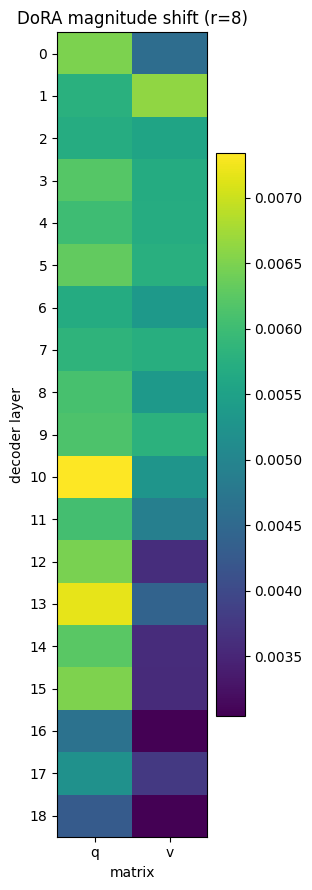


Near-zero shift everywhere => DoRA barely moved the backbone, so the gain
(if any) came from the head. That is itself a useful finding.


In [ ]:
# CELL 11 — DID DoRA HELP? + CRF delta + magnitude interpretation

import pandas as pd
import matplotlib.pyplot as plt

# (a) CRF decode vs raw argmax, same weights
f1c, accc, yt, ypc = score(swa_dev_e, dev_docs, crf=swa, use_crf=True)
f1a, acca, _,  ypa = score(swa_dev_e, dev_docs, crf=swa, use_crf=False)
print("Dev, identical weights, two decodes:")
print(f"  argmax  F1={f1a:.4f} acc={acca:.4f}")
print(f"  Viterbi F1={f1c:.4f} acc={accc:.4f}   delta {f1c-f1a:+.4f}")

def runlen(seq):
    r, out = 1, []
    for i in range(1, len(seq)):
        if seq[i] == seq[i-1]: r += 1
        else: out.append(r); r = 1
    out.append(r); return float(np.mean(out))
print(f"\nrun length  gold {runlen(yt):.2f} | argmax {runlen(ypa):.2f} | "
      f"Viterbi {runlen(ypc):.2f}   (gold pool: 7.49)")
print("If Viterbi overshoots gold, lower crf_lr; if it undershoots, raise it.")

# (b) which matrices did DoRA actually rescale?
def dora_magnitude(mod, name="default"):
    mv = getattr(mod, "lora_magnitude_vector", None)
    if mv is None: return None
    if isinstance(mv, torch.nn.ModuleDict) and name in mv:
        s = mv[name]
        return s.weight.detach().cpu() if hasattr(s, "weight") else s.detach().cpu()
    if isinstance(mv, torch.nn.ParameterDict) and name in mv:
        return mv[name].detach().cpu()
    return None

rows = []
for nm, mod in decoder.named_modules():
    m = dora_magnitude(mod)
    if m is None: continue
    g = re.search(r"layers\.(\d+)\.attn\.([qkvo])", nm)
    if not g: continue
    li, mn = int(g.group(1)), g.group(2)
    if (li, mn) not in pre_norms: continue
    m0 = pre_norms[(li, mn)].flatten().float()
    m1 = m.flatten().float()
    if m1.shape != m0.shape: continue
    rel = ((m1 - m0) / m0.clamp(min=1e-6)).abs()
    rows.append({"layer": li, "matrix": mn,
                 "mean_rel_shift": float(rel.mean()),
                 "max_rel_shift": float(rel.max())})

if rows:
    df = pd.DataFrame(rows).sort_values(["layer", "matrix"])
    piv = df.pivot(index="layer", columns="matrix", values="mean_rel_shift")
    print("\nDoRA magnitude shift |m_learned - ||W||| / ||W||, per layer x matrix:")
    print(piv.round(4))
    print("\nby matrix:"); print(df.groupby("matrix")["mean_rel_shift"].mean().round(4))
    print("\nmost adapted layers:")
    print(df.groupby("layer")["mean_rel_shift"].mean().sort_values(ascending=False).head(5).round(4))
    fig, ax = plt.subplots(figsize=(3.2, 9))
    im = ax.imshow(piv.values, cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(piv.columns))); ax.set_xticklabels(piv.columns)
    ax.set_yticks(range(len(piv.index)));   ax.set_yticklabels(piv.index)
    ax.set_xlabel("matrix"); ax.set_ylabel("decoder layer")
    ax.set_title(f"DoRA magnitude shift (r={CFG.r})")
    plt.colorbar(im); plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "dora_magnitude.png", dpi=120); plt.show()
    print("\nNear-zero shift everywhere => DoRA barely moved the backbone, so the gain")
    print("(if any) came from the head. That is itself a useful finding.")
else:
    print("\nNo DoRA magnitude vectors found (use_dora=False => plain LoRA).")

In [ ]:
# CELL 12 — DEV REPORT + CL/IT SPLIT

names = [ID2LABEL[i] for i in range(NUM_LABELS)]
print(f"DEV macro-F1 = {f1c:.4f}  acc = {accc:.4f}\n")
print(classification_report(yt, ypc, labels=list(range(NUM_LABELS)),
                            target_names=names, digits=4, zero_division=0))
sup = np.bincount(yt, minlength=NUM_LABELS)
ok = [i for i in range(NUM_LABELS) if sup[i] > 0]
print(f"over supported labels only ({len(ok)}/{NUM_LABELS}): "
      f"{f1_score(yt, ypc, labels=ok, average='macro', zero_division=0):.4f}")

for tag, grp in (("CL", cl_dev), ("IT", it_dev)):
    f, a, _, _ = score(swa_dev_e, grp, crf=swa)
    print(f"{tag} dev: F1={f:.4f} acc={a:.4f}")

DEV macro-F1 = 0.4231  acc = 0.5537

                        precision    recall  f1-score   support

                  Fact     0.7303    0.6892    0.7092       444
                 Issue     0.8000    0.2667    0.4000        15
    ArgumentPetitioner     0.5556    0.3000    0.3896       400
    ArgumentRespondent     0.4051    0.6434    0.4972       272
               Statute     0.8922    0.7583    0.8198       120
               Dissent     0.0000    0.0000    0.0000         0
   PrecedentReliedUpon     0.5490    0.4409    0.4891       254
PrecedentNotReliedUpon     0.3939    0.2600    0.3133        50
    PrecedentOverruled     0.0000    0.0000    0.0000         0
    RulingByLowerCourt     0.4310    0.2451    0.3125       102
    RatioOfTheDecision     0.4888    0.7593    0.5948       403
  RulingByPresentCourt     0.7647    0.5306    0.6265        49
                  None     0.6154    0.2424    0.3478        33

              accuracy                         0.5537      2142
 

In [ ]:
# CELL 13 — SUBMISSION (plateau-averaged emissions, whole documents)

predictions = {}
for d in test_docs:
    e = torch.tensor(swa_test_e[d["doc_id"]], dtype=torch.float32, device=DEVICE)
    path = swa.viterbi(e)
    assert len(path) == len(d["sentences"]), d["doc_id"]
    predictions[d["doc_id"]] = [ID2LABEL[int(p)] for p in path]

assert len(predictions) == len(test_docs)
assert all(l in LABEL2ID for v in predictions.values() for l in v)

pp = OUTPUT_DIR / "prediction.json"
with open(pp, "w", encoding="utf-8") as f:
    json.dump(predictions, f, indent=2, ensure_ascii=False)
zp = OUTPUT_DIR / "submission.zip"
with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as zf:
    zf.write(pp, "prediction.json")
print(f"Saved {zp}")

pc = Counter(l for v in predictions.values() for l in v)
ptot = sum(pc.values()); ttot = sum(cnt.values())
print(f"\nPredicted {len(pc)}/{NUM_LABELS} distinct labels")
print(f"{'label':<26}{'pred':>7}{'pred%':>8}{'train%':>9}")
for i in sorted(range(NUM_LABELS), key=lambda i: -cnt.get(i, 0)):
    l = ID2LABEL[i]
    print(f"{l:<26}{pc.get(l,0):>7}{100*pc.get(l,0)/ptot:>7.2f}%{100*cnt.get(i,0)/ttot:>8.2f}%")

json.dump({"best_single_epoch_dev": float(best_f1), "best_epoch": int(best_ep),
           "swa_dev": float(swa_f1), "crf_delta_dev": float(f1c - f1a),
           "use_dora": bool(CFG.use_dora), "r": int(CFG.r),
           "history": history},
          open(OUTPUT_DIR / "run_summary.json", "w"), indent=2)
print(f"\nSummary -> {OUTPUT_DIR/'run_summary.json'}")

Saved /content/drive/MyDrive/CS781_Phase3_DoRA_CRF_outputs/submission.zip

Predicted 11/13 distinct labels
label                        pred   pred%   train%
RatioOfTheDecision            605  27.54%   25.53%
Fact                          417  18.98%   24.33%
PrecedentReliedUpon           491  22.35%   11.55%
ArgumentPetitioner            147   6.69%    9.58%
ArgumentRespondent            173   7.87%    8.00%
Statute                       168   7.65%    6.52%
RulingByLowerCourt            114   5.19%    5.19%
PrecedentNotReliedUpon         18   0.82%    3.38%
RulingByPresentCourt           40   1.82%    1.82%
None                           14   0.64%    1.76%
Dissent                         0   0.00%    1.69%
Issue                          10   0.46%    0.64%
PrecedentOverruled              0   0.00%    0.02%

Summary -> /content/drive/MyDrive/CS781_Phase3_DoRA_CRF_outputs/run_summary.json
